(506, 14)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   crim     506 non-null    float64
 1   zn       506 non-null    float64
 2   indus    506 non-null    float64
 3   chas     506 non-null    int64  
 4   nox      506 non-null    float64
 5   rm       501 non-null    float64
 6   age      506 non-null    float64
 7   dis      506 non-null    float64
 8   rad      506 non-null    int64  
 9   tax      506 non-null    int64  
 10  ptratio  506 non-null    float64
 11  b        506 non-null    float64
 12  lstat    506 non-null    float64
 13  medv     506 non-null    float64
dtypes: float64(11), int64(3)
memory usage: 55.5 KB
None
             crim          zn       indus        chas         nox          rm  \
count  506.000000  506.000000  506.000000  506.000000  506.000000  501.000000   
mean     3.613524   11.363636   11.136779    0.069170    0

/tmp/ipykernel_1697/2456020884.py:20: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


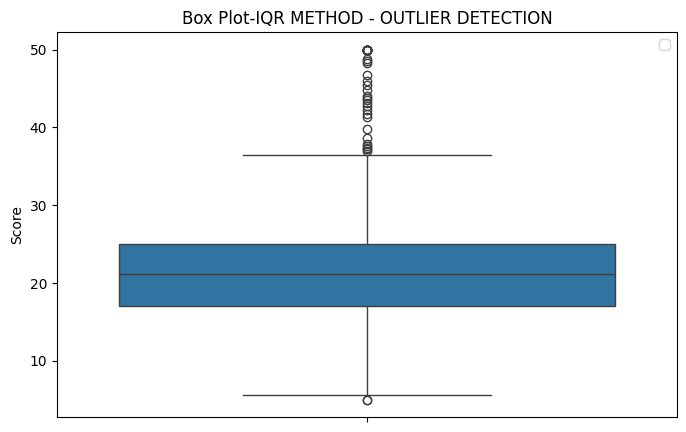


IQR Lower Limit: 5.06, Upper Limit: 36.96
Number of IQR Outliers detected: 40

Z-Score Lower Limit: -5.06, Upper Limit: 50.12
Number of Z-Score Outliers detected: 0


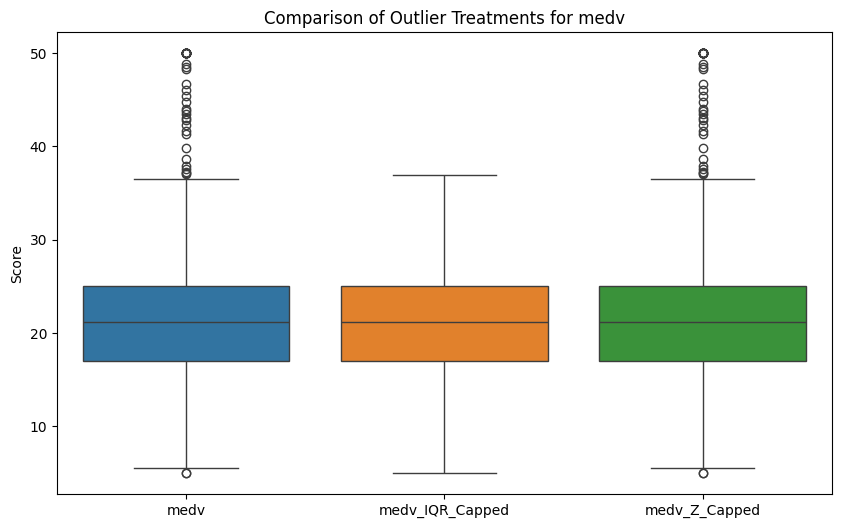

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
df = pd.read_csv("BostonHousing.csv")
df.head()
print(df.shape)
print(df.info())
print(df.describe())
col = 'medv'
print("First 5 rows of dataset:")
print(df[[col]].head())

plt.figure(figsize=(8, 5))
sns.boxplot(y=df[col])

plt.title(f"Box Plot-IQR METHOD - OUTLIER DETECTION")
plt.ylabel("Score")
plt.legend()
plt.show()

Q1 = df[col].quantile(0.25)
Q3 = df[col].quantile(0.75)
IQR = Q3 - Q1

lower_limit_iqr = Q1 - 1.5 * IQR
upper_limit_iqr = Q3 + 1.5 * IQR

outliers_iqr = df[(df[col] < lower_limit_iqr) | (df[col] > upper_limit_iqr)]
print(f"\nIQR Lower Limit: {lower_limit_iqr:.2f}, Upper Limit: {upper_limit_iqr:.2f}")
print(f"Number of IQR Outliers detected: {len(outliers_iqr)}")

df[f'{col}_IQR_Capped'] = df[col].clip(lower=lower_limit_iqr, upper=upper_limit_iqr)

df['Z_score'] = stats.zscore(df[col])
z_outliers = df[abs(df['Z_score']) > 3]

mean_val = df[col].mean()
std_val = df[col].std()
lower_limit_z = mean_val - 3 * std_val
upper_limit_z = mean_val + 3 * std_val

print(f"\nZ-Score Lower Limit: {lower_limit_z:.2f}, Upper Limit: {upper_limit_z:.2f}")
print(f"Number of Z-Score Outliers detected: {len(z_outliers)}")

df[f'{col}_Z_Capped'] = df[col].clip(lower=lower_limit_z, upper=upper_limit_z)

plt.figure(figsize=(10, 6))
sns.boxplot(data=df[[col, f'{col}_IQR_Capped', f'{col}_Z_Capped']])
plt.title(f"Comparison of Outlier Treatments for {col}")
plt.ylabel("Score")
plt.show()